# OTEC cold-water pipe dynamics, 61 m model 
Based on *Dynamics of offshore structures*, J. F. Wilson (Chapter 10).

Governing equation (lateral deflection $v(x,t)$, $x$ measured from the top):

$$EI\,v'''' - \frac{\partial P}{\partial x}\,v' - P\,v'' + (\hat m + m_a)\,\ddot v = \hat q_{wave}(x,t)$$

**Changes relative to `otec_v3d2c_61m.ipynb`**

| # | Problem in the original | Fix here |
|---|---|---|
| 1 | Stencil centred on node *i* while the unknown was node *i+2* (terms evaluated at 3 different places) | All derivatives, $P$ and $\partial P/\partial x$ are evaluated at the same node; the discretisation is built as matrices |
| 2 | Time derivative mixed nodes and used a future value that was still zero | Proper time integration (implicit Newmark, average acceleration, unconditionally stable) |
| 3 | Negative indices wrapped to the far end of the pipe; no real boundary conditions | Explicit ghost-node relations for the top and bottom boundary conditions |
| 4 | Random phases redrawn on every call | Phases drawn **once** (seeded generator) and reused |
| 5 | `sympy` `diff`/`solve` at every node and step (2 days 5.7 h) | Analytic $H''$, $P$, $\partial P/\partial x$; vectorised loads; runs in seconds |
| 6 | Time step from axial wave speed (wrong criterion for bending) | Implicit scheme, so $\Delta t$ is chosen for accuracy; a convergence check is included |
| 7 | Only 8 intervals ($h=7.6$ m) for a load that decays within metres of the surface | $h = 1$ m by default, with a mesh-convergence check |
| 8 | `T` overwritten by `meshgrid`; `plt.plot(T, v[2])` with a 2-D `T` | Separate names; clean plots |

**Modelling choices you should check against Wilson**
* Top boundary (x = 0): the sway motion $S(t)$ is prescribed, and the pipe is free to rotate ($v''=0$). The spring stiffness `K` from the original constants is **not** used. Change `build_operators` if Wilson's top condition is a spring.
* Bottom boundary (x = L): free end, $M=EIv''=0$ and $V=EIv'''=0$ (the axial-force contribution to shear is neglected).
* Loads, sway and heave are ramped in smoothly over `T_RAMP` seconds to avoid a start-up shock (the pipe starts at rest). Set `T_RAMP = 0` to disable.
* As in the original, heave, sway and wave-kinematics components use independent random phases.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve
from time import perf_counter

## Parameters

In [2]:
# --- wave spectrum (Pierson-Moskowitz) and barge motion ---
A = 0.78
B = 0.0311
omega_b = 0.503     # barge heave RAO cut-off
omega_N = 1.5       # highest frequency
omega_p = 0.4       # peak frequency (sway)
N = 15              # number of frequency components
e1 = 0.093
e2 = 0.05

# --- pipe / fluid ---
CA = 1
CM = 2
d = 1067            # water depth
D = 9.144           # pipe diameter
EI = 3.94e11
# for cables (of small diameters): EI = E*np.pi/64*D**4
g = 9.81
L = 61              # pipe length
M0 = 4.54e4         # or 2.27e5
M1 = 0.6*M0
m_hat = 6.43e4      # pipe mass per unit length
m1_hat = 1.25e3     # (submerged weight related) mass per unit length used in P
rho = 962

# --- numerical settings ---
T = 600.0           # simulated time [s]
m = 61              # number of intervals along the pipe (h = L/m)
dt = 0.05           # time step [s]
T_RAMP = 60.0       # smooth start-up of the forcing [s]
SEED = 42           # random-phase realisation

d_omega = omega_N/N
w = d_omega*np.arange(1, N+1)       # frequency components

## Wave spectrum, heave response, and random phases (drawn once)

In [3]:
def S_eta(omega):
    # Pierson-Moskowitz spectrum
    return A*omega**(-5)*np.exp(-B/omega**4)

def eta(omega, del_omega):
    return np.sqrt(2*S_eta(omega)*del_omega)

def R(omega):
    # heave response factor of the barge
    omega = np.asarray(omega, dtype=float)
    return np.where(omega <= omega_b, 1.0,
           np.where(omega <= omega_N, 1 - (omega - omega_b)/(omega_N - omega_b), 0.0))

eta_w = eta(w, d_omega)
R_w = R(w)

# one fixed random realisation (this is what the original redrew on every call)
rng = np.random.default_rng(SEED)
phi_H = rng.uniform(0, 2*np.pi, N)        # heave
phi_S = rng.uniform(0, 2*np.pi, N)        # sway (components above omega_p)
phi_Sp = rng.uniform(0, 2*np.pi)          # sway (peak component)
phi_u = rng.uniform(0, 2*np.pi, N)        # wave kinematics

print("eta(omega_N) =", eta(omega_N, d_omega))

eta(omega_N) = 0.14288945193592165


## Time histories of the forcing (analytic, vectorised)

* Heave acceleration: $H''(t) = -\sum_i \omega_i^2 R_i \eta_i \cos(\omega_i t + \varphi_i)$
* Axial force: $P(x,t) = M_1 g + (L-x)(\hat m_1 g + \hat m H'') + M_0 H''$, so $\partial P/\partial x = -(\hat m_1 g + \hat m H'')$
* Sway: $S(t)=\eta(\omega_p)\sin(e_1\omega_p t+\varphi_p)+\sum_{\omega_i>\omega_p} e_2\,\eta_i \sin(e_1\omega_i t+\varphi_i)$
* Morison wave load per unit length (inertia part; the added-mass term goes to the left-hand side):
  $F_w = 1.1\cdot\tfrac14\pi C_M\rho D^2\sum_i \omega_i^2\eta_i \dfrac{e^{k_i(z+d)}}{\sinh(k_i d)}\sin(\omega_i t+\varphi_i)$, $k_i=\omega_i^2/g$, $z=-x$.
  The ratio is evaluated as $2e^{k z}/(1-e^{-2kd})$, which is identical but cannot overflow.

In [4]:
def ramp(t):
    if T_RAMP <= 0:
        return np.ones_like(t)
    s = np.clip(t/T_RAMP, 0, 1)
    return 0.5*(1 - np.cos(np.pi*s))

def heave_acc(t):
    # H''(t) for an array of times
    t = np.atleast_1d(t)
    return -(w**2*R_w*eta_w*np.cos(np.outer(t, w) + phi_H)).sum(axis=1)

def sway(t):
    t = np.atleast_1d(t)
    mask = w > omega_p + 1e-12          # i from int(omega_p/d_omega + 1) to N
    peak = eta(omega_p, d_omega)*np.sin(e1*omega_p*t + phi_Sp)
    rest = (e2*eta_w[mask]*np.sin(np.outer(t, e1*w[mask]) + phi_S[mask])).sum(axis=1)
    return peak + rest

def wave_load(x, t):
    # Morison inertia wave load F_w at positions x (n_x,) and times t (n_t,) -> (n_t, n_x)
    x = np.atleast_1d(x); t = np.atleast_1d(t)
    k = w**2/g
    z = -x
    shape = 2*np.exp(np.outer(z, k))/(1 - np.exp(-2*k*d))        # = exp(k(z+d))/sinh(kd)
    amp = shape*(w**2*eta_w)                                      # (n_x, N)
    return 1.1*0.25*np.pi*CM*rho*D**2*np.sin(np.outer(t, w) + phi_u) @ amp.T

Ma = 0.25*np.pi*CA*rho*D**2        # added mass per unit length
M_eff = m_hat + Ma

## Discretisation (fixes 1 and 3)

Nodes $i=0\ldots m$ at $x_i=ih$. Node 0 is prescribed (sway). For the 5-point stencil, ghost values
$v_{-2},v_{-1},v_{m+1},v_{m+2}$ are expressed linearly through the real nodes:

* top: $v''=0$ gives $v_{-1}=2v_0-v_1$ (and $v_{-2}$ by linear extension)
* bottom: $v''=0$ gives $v_{m+1}=2v_m-v_{m-1}$ and $v'''=0$ gives $v_{m+2}=2v_{m+1}-2v_{m-1}+v_{m-2}$

All derivatives at node $i$ use the same centred stencil, so the three terms of the equation refer to the same point.

In [5]:
def build_operators(m):
    h = L/m
    # ve[j+2] = v_j for j = -2..m+2, expressed as ve = G @ v  (v = nodes 0..m)
    G = np.zeros((m+5, m+1))
    for i in range(m+1):
        G[i+2, i] = 1.0
    # top: v''=0 at node 0
    G[1, 0] += 2.0; G[1, 1] += -1.0
    G[0, :] = 2*G[1, :]; G[0, 0] += -1.0
    # bottom: free end (M=0, V=0)
    G[m+3, m] += 2.0; G[m+3, m-1] += -1.0
    G[m+4, :] = 2*G[m+3, :]; G[m+4, m-1] += -2.0; G[m+4, m-2] += 1.0
    idx = np.arange(1, m+1)                      # unknown nodes 1..m (node 0 prescribed)
    K4 = (G[idx] - 4*G[idx+1] + 6*G[idx+2] - 4*G[idx+3] + G[idx+4])/h**4
    K2 = (G[idx+1] - 2*G[idx+2] + G[idx+3])/h**2
    K1 = (G[idx+3] - G[idx+1])/(2*h)
    return h, K4, K2, K1

## Time integration (fixes 2 and 6)

Newmark average-acceleration ($\beta=1/4,\ \gamma=1/2$) is unconditionally stable for the linear problem, so $\Delta t$ is set by accuracy (shortest wave period is $2\pi/1.5\approx4.2$ s), not by the very small explicit limit $h^2/(2\sqrt{EI/\hat m})$.
At every step the stiffness matrix $K(t)=EI\,K_4-\tfrac{\partial P}{\partial x}K_1-\mathrm{diag}(P)K_2$ is rebuilt from the analytic $P$.

In [6]:
def run(m=m, dt=dt, T=T, verbose=False):
    h, K4, K2, K1 = build_operators(m)
    x = np.arange(m+1)*h
    n = int(round(T/dt))
    t = np.arange(n+1)*dt

    # forcing for all time levels (vectorised, ramped)
    rt = ramp(t)
    u0 = sway(t)*rt                                   # prescribed top motion
    Hdd = heave_acc(t)*rt                             # heave acceleration
    F = wave_load(x[1:], t)*rt[:, None]               # (n+1, m)

    beta, gamma = 0.25, 0.5
    c0 = 1/(beta*dt**2)
    u = np.zeros((n+1, m+1))
    u[:, 0] = u0
    vel = np.zeros(m); acc = np.zeros(m)              # velocities / accelerations of nodes 1..m
    xi = x[1:]

    def stiffness(j):
        dPdx = -(m1_hat*g + m_hat*Hdd[j])
        P = M1*g + (L - xi)*(m1_hat*g + m_hat*Hdd[j]) + M0*Hdd[j]
        return EI*K4 - dPdx*K1 - P[:, None]*K2

    # initial acceleration from equilibrium at t = 0 (pipe at rest, top displaced u0[0]*ramp(0)=0)
    K = stiffness(0)
    acc = (F[0] - K @ u[0])/M_eff

    I = np.eye(m)
    for j in range(n):
        K = stiffness(j+1)
        lhs = K[:, 1:] + (M_eff*c0)*I
        rhs = (F[j+1] - K[:, 0]*u0[j+1]
               + M_eff*(c0*u[j, 1:] + vel/(beta*dt) + (1/(2*beta) - 1)*acc))
        u_new = solve(lhs, rhs, assume_a='gen')
        acc_new = c0*(u_new - u[j, 1:]) - vel/(beta*dt) - (1/(2*beta) - 1)*acc
        vel = vel + dt*((1 - gamma)*acc + gamma*acc_new)
        acc = acc_new
        u[j+1, 1:] = u_new
    return x, t, u.T          # v[node, time], same layout as the original notebook

## Run

In [7]:
t0 = perf_counter()
x, t, v = run()
print(f"v.shape = {v.shape}   run time = {perf_counter()-t0:.1f} s")
print("max / min deflection:", v.max(), v.min())

v.shape = (62, 12001)   run time = 1.1 s
max / min deflection: 23.585116811892973 -15.639942896202138


## Checks

The original `max(v)/L < 1` test only said the deflection was smaller than the pipe length. Here we check that the solution is finite and that the response is not growing in time (RMS of the last third vs. the middle third, after the ramp).

In [8]:
finite = np.isfinite(v).all()
n_t = v.shape[1]
mid = v[:, n_t//3: 2*n_t//3]
last = v[:, 2*n_t//3:]
growth = np.sqrt((last**2).mean())/np.sqrt((mid**2).mean())
print("finite:", finite)
print(f"RMS(last third)/RMS(middle third) = {growth:.2f}")
if finite and v.max() - v.min() < L and growth < 1.5:
    print("Stable: bounded response")
else:
    print("Unbounded pipe response")
ind = np.unravel_index(np.argmax(np.abs(v)), v.shape)
print(f"largest |v| = {abs(v[ind]):.3f} m at x = {x[ind[0]]:.1f} m, t = {t[ind[1]]:.1f} s")

finite: True
RMS(last third)/RMS(middle third) = 0.54
Stable: bounded response
largest |v| = 23.585 m at x = 61.0 m, t = 257.3 s


## Convergence checks (time step and mesh)

In [9]:
def summary(xx, tt, vv):
    sel = tt > 2*T_RAMP
    return np.abs(vv[:, sel]).max(), np.sqrt((vv[:, sel]**2).mean())

print(f"{'case':<22}{'max|v| [m]':>12}{'rms [m]':>10}")
for label, kw in [("base (m=61, dt=0.05)", dict()),
                  ("dt = 0.025",          dict(dt=0.025)),
                  ("dt = 0.1",            dict(dt=0.1)),
                  ("m = 122 (h=0.5 m)",   dict(m=122)),
                  ("m = 30  (h=2 m)",     dict(m=30))]:
    xx, tt, vv = run(**kw)
    mx, rms = summary(xx, tt, vv)
    print(f"{label:<22}{mx:12.4f}{rms:10.4f}")

case                    max|v| [m]   rms [m]
base (m=61, dt=0.05)       23.5851    4.5526
dt = 0.025                 23.5856    4.5526
dt = 0.1                   23.5827    4.5525
m = 122 (h=0.5 m)          23.5865    4.5459
m = 30  (h=2 m)            23.5786    4.5661


## Visualisation

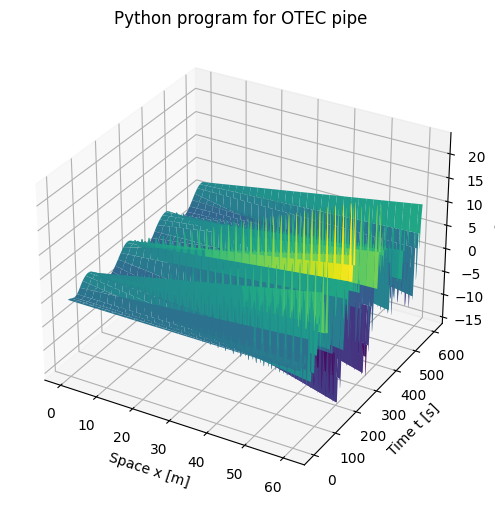

In [10]:
Xg, Tg = np.meshgrid(x, t[::10])                  # do not overwrite the scalar T
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(Xg, Tg, v[:, ::10].T, cmap='viridis')
ax.set_xlabel('Space x [m]'); ax.set_ylabel('Time t [s]'); ax.set_zlabel('v [m]')
plt.title('Python program for OTEC pipe')
plt.show()

x =  15.0 m: max v = 7.399 m, min v = -5.356 m
x =  30.0 m: max v = 12.664 m, min v = -8.698 m
x =  45.0 m: max v = 17.945 m, min v = -12.054 m
x =  61.0 m: max v = 23.585 m, min v = -15.640 m


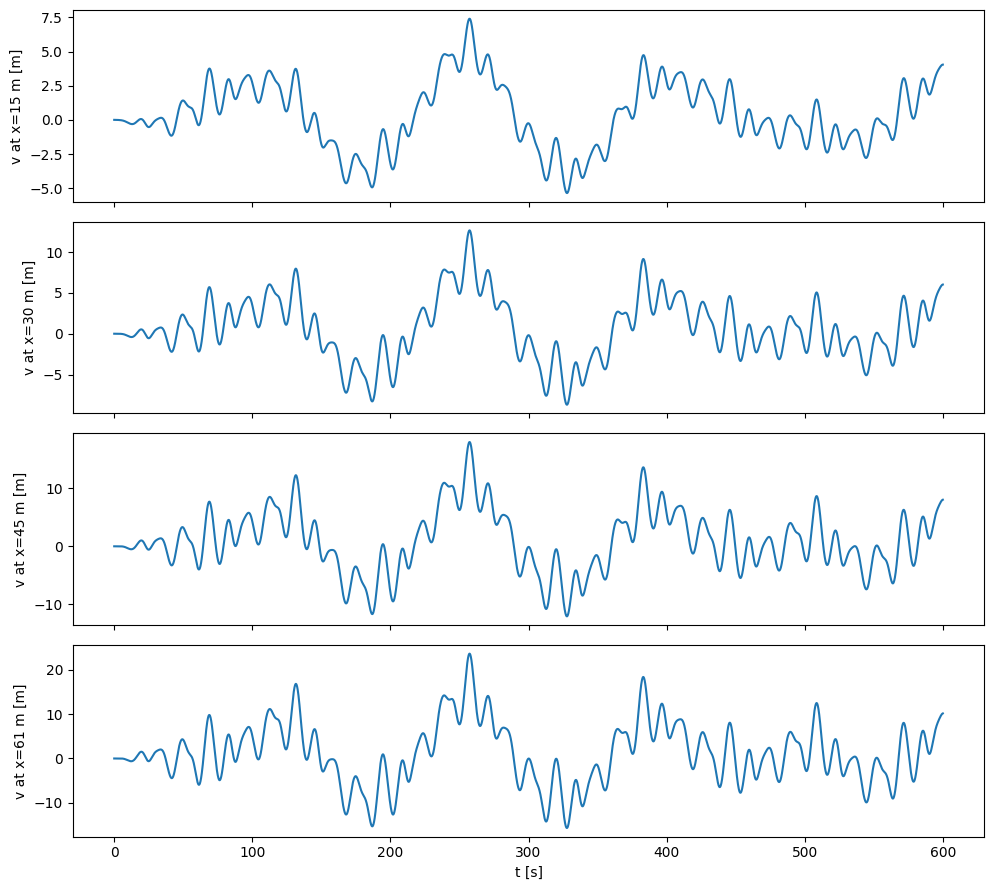

In [11]:
# time histories at selected depths
fig, axs = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
for a, xs in zip(axs, [15, 30, 45, L]):
    i = int(round(xs/(x[1]-x[0])))
    a.plot(t, v[i], '-')
    a.set_ylabel(f'v at x={x[i]:.0f} m [m]')
    print(f"x = {x[i]:5.1f} m: max v = {v[i].max():.3f} m, min v = {v[i].min():.3f} m")
axs[-1].set_xlabel('t [s]')
plt.tight_layout(); plt.show()

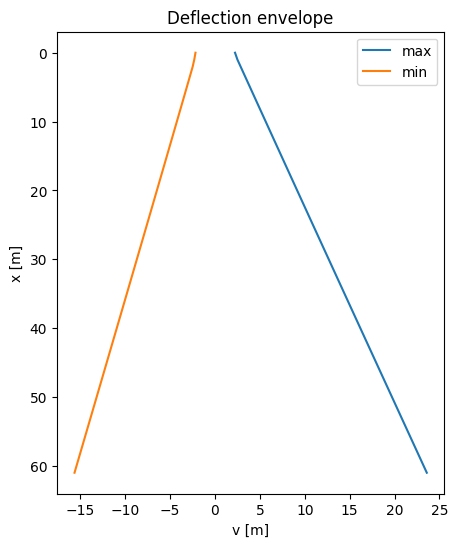

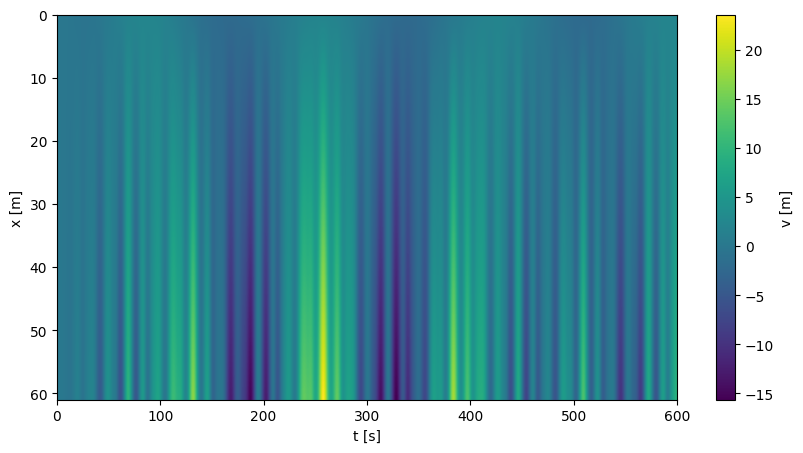

In [12]:
# envelope along the pipe
plt.figure(figsize=(5, 6))
plt.plot(v.max(axis=1), x, label='max')
plt.plot(v.min(axis=1), x, label='min')
plt.gca().invert_yaxis()
plt.xlabel('v [m]'); plt.ylabel('x [m]'); plt.legend(); plt.title('Deflection envelope')
plt.show()

plt.figure(figsize=(10, 5))
plt.imshow(v, aspect='auto', extent=[t[0], t[-1], x[-1], x[0]], cmap='viridis')
plt.colorbar(label='v [m]'); plt.xlabel('t [s]'); plt.ylabel('x [m]')
plt.show()

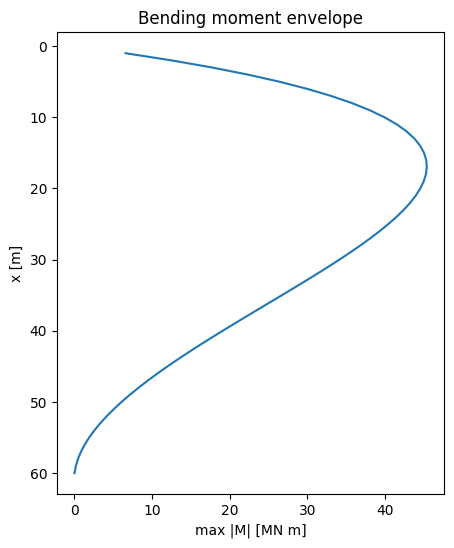

In [13]:
# bending moment M = EI v'' (the original notebook ended with a note about moments, Wilson eq. 10.135)
h = x[1] - x[0]
Mom = EI*(v[:-2] - 2*v[1:-1] + v[2:])/h**2
plt.figure(figsize=(5, 6))
plt.plot(np.abs(Mom).max(axis=1)/1e6, x[1:-1])
plt.gca().invert_yaxis()
plt.xlabel('max |M| [MN m]'); plt.ylabel('x [m]'); plt.title('Bending moment envelope')
plt.show()